In [1]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import catboost

In [3]:
df = pd.read_csv("Data/data_kern.csv")

In [4]:
df

,Calibration,Well,Sample,Depth,Stratigraphy,Mg,Al,Si,P,S,...,Sr,Zr,Mo,Ba,Pb,Th,U,Y,Cd,V
0,LE-FP,C3,1,2868.11,Fr,1.821148,7.515664,18.611483,0.299690,10.465318,...,0.017295,0.005169,0.006378,0.390684,0.0011,0.0034,0.0330,NaN,NaN,0.0
1,LE-FP,C3,2,2868.30,Fr,1.266357,7.461183,16.904798,0.000000,14.653735,...,0.009028,0.003092,0.007169,0.179474,0.0019,0.0000,0.0012,NaN,NaN,0.0
2,LE-FP,C3,3,2868.45,Fr,1.724880,7.150965,18.068731,0.000000,13.442425,...,0.018256,0.005030,0.006039,0.522104,0.0015,0.0000,0.0018,NaN,NaN,0.0
3,LE-FP,C3,4,2868.64,Fr,1.646439,8.260792,21.260196,0.000000,10.257598,...,0.011463,0.004061,0.005446,0.222917,0.0021,0.0000,0.0017,NaN,NaN,0.0
4,LE-FP,C3,5,2868.78,Fr,1.847176,7.757235,19.837340,0.000000,10.623499,...,0.016122,0.002446,0.006519,0.494492,0.0023,0.0000,0.0036,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3111,LE-FP,C7,362,2697.50,Tum,1.583924,10.335025,27.434503,0.029277,0.622963,...,0.012094,0.011722,0.000000,0.158503,NaN,NaN,NaN,NaN,NaN,NaN
3112,LE-FP,C7,363,2697.78,Tum,1.491458,7.860884,29.874495,0.020000,0.691707,...,0.011974,0.007845,0.000000,0.133802,NaN,NaN,NaN,NaN,NaN,NaN
3113,LE-FP,C7,364,2697.84,Tum,1.459012,11.210366,28.113407,0.052834,0.137574,...,0.012214,0.015968,0.000000,0.160868,NaN,NaN,NaN,NaN,NaN,NaN
3114,LE-FP,C7,365,2698.97,Tum,1.300348,1.489742,2.630132,0.000000,31.978827,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


**Отобранные элементы с доставерными определениями**

In [5]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [6]:
cols_to_keep = elements + ['Well', 'Sample',	'Depth',	'Stratigraphy']
df_filtered = df[cols_to_keep].query("Stratigraphy != 'Tum'").copy()

**Замена пачек на цифровые коды**

In [7]:
def to_str_key(val):
    try:
        return str(int(val))
    except (ValueError, TypeError):
        return str(val).strip()

df_filtered['Strat'] = df_filtered['Stratigraphy'].apply(to_str_key)

In [8]:
formation_map = {
    'Abl': 0,
    'A0': 1,
    '1': 2,
    '2a': 3,
    '2b': 4,
    '3': 5,
    '4a': 6,
    '4b': 7,
    '5a': 8,
    '5b': 9,
    '6': 10,
    'Fr': 11
}

df_filtered['Strat'] = df_filtered['Strat'].map(formation_map)

**5-фолдовая кросс-валидация по скважинам (внутренне разбиение также по скважинам)**

Валидационный фолд (1/5 скважин)
Обучающие скважины (4/5)
Inner train (4/5 от обучающих) 
Inner val (1/5 от обучающих)

Обучаем модель на inner_train, контролируем на inner_val. use_best_model=True

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
  Inner train wells: ['A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'D1']
  Inner val wells:   ['A2', 'C7']
  Inner train: 1916 проб, Inner val: 536 проб

Лучшие параметры: {'depth': 8, 'iterations': 1000, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
F1 macro (train): 0.9243
F1 macro (val):   0.4219
Gap (train-val):  0.5024

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9351    0.5714    0.7094       126
           1     0.4231    0.2157    0.2857        51
           2     0.2357    0.7174    0.3548        46
           3     0.6912    0.6528    0.6714        72
           4     0.5179    0.6444    0.5743        45
           5     0.0000    0.0000    0.0000         7
           6     0.2000    0.0698    0.1034        43
           7     0.3023    0.3514    0.3250      

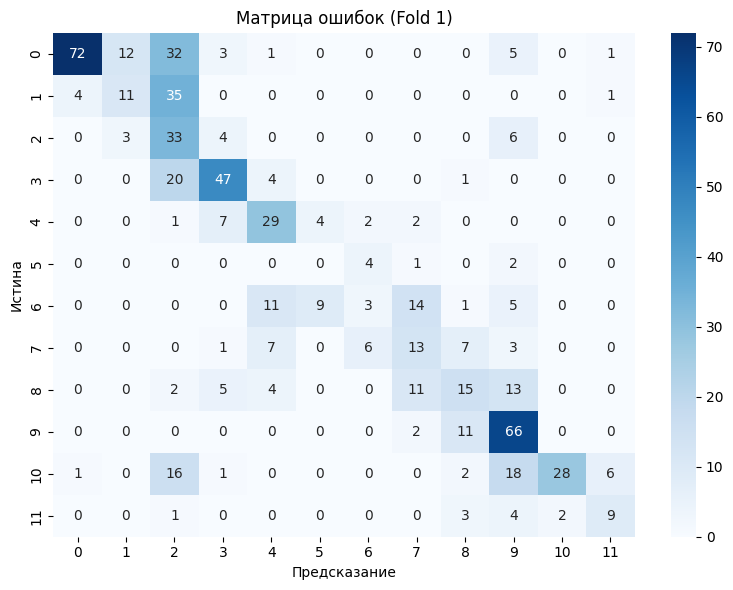

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
  Inner train wells: ['A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Inner val wells:   ['A1']
  Inner train: 1939 проб, Inner val: 500 проб

Лучшие параметры: {'depth': 8, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
F1 macro (train): 0.8605
F1 macro (val):   0.6553
Gap (train-val):  0.2052

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8293    0.8718    0.8500        78
           1     0.7000    0.4773    0.5676        44
           2     0.5918    0.5800    0.5859        50
           3     0.7568    0.7778    0.7671        72
           4     0.6711    0.6623    0.6667        77
           5     0.4595    0.4595    0.4595        37
           6     0.4091    0.3214    0.3600        28
           7     0.4815    0.4643    0.4727        28


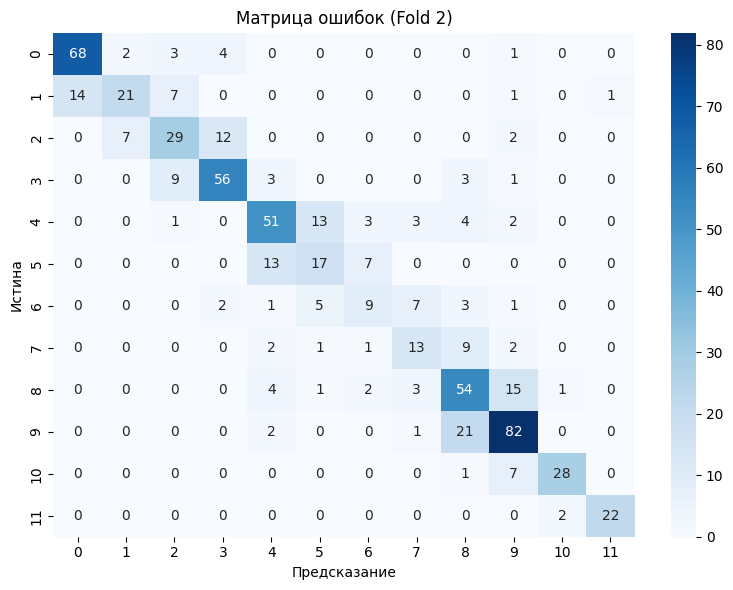

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
  Inner train wells: ['A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Inner val wells:   ['A1']
  Inner train: 1993 проб, Inner val: 500 проб

Лучшие параметры: {'depth': 4, 'iterations': 1000, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
F1 macro (train): 0.8063
F1 macro (val):   0.5750
Gap (train-val):  0.2313

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9571    0.9710    0.9640        69
           1     0.4667    0.5000    0.4828        14
           2     0.5000    0.6000    0.5455        40
           3     0.6346    0.6600    0.6471        50
           4     0.6667    0.4444    0.5333        54
           5     0.5417    0.3611    0.4333        36
           6     0.3235    0.6111    0.4231        18
           7     0.4286    0.1579    0.2308        38
 

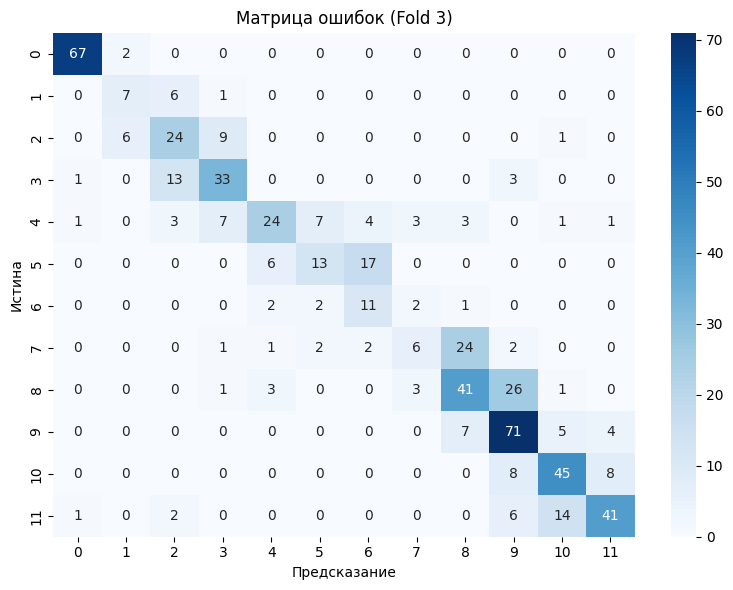

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
  Inner train wells: ['A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Inner val wells:   ['A1']
  Inner train: 2000 проб, Inner val: 500 проб

Лучшие параметры: {'depth': 5, 'iterations': 1000, 'l2_leaf_reg': 3, 'learning_rate': 0.15}
F1 macro (train): 0.8433
F1 macro (val):   0.5932
Gap (train-val):  0.2501

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9691    0.9792    0.9741        96
           1     0.8182    0.4737    0.6000        19
           2     0.7143    0.8929    0.7937        28
           3     0.8000    0.7500    0.7742        32
           4     0.4231    0.7097    0.5301        31
           5     0.2222    0.2222    0.2222        45
           6     0.2222    0.0976    0.1356        41
           7     0.4500    0.1500    0.2250        60


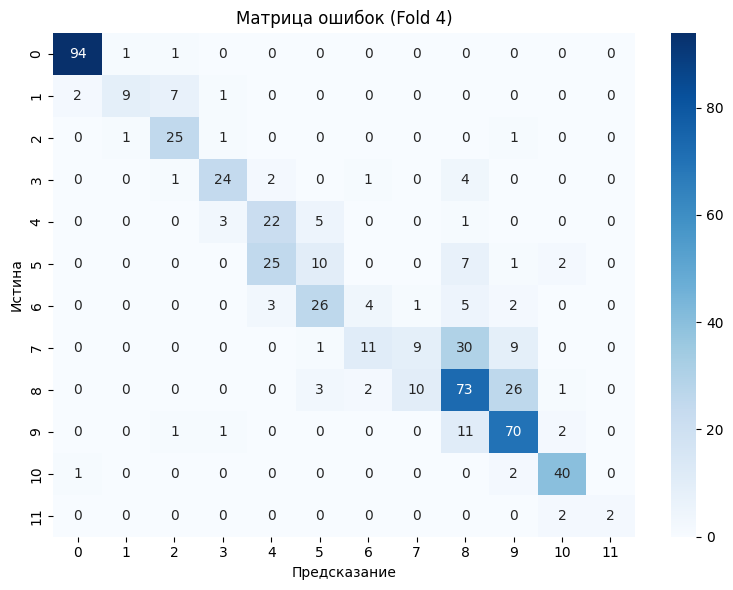

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
  Inner train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Inner val wells:   ['A1']
  Inner train: 2012 проб, Inner val: 500 проб

Лучшие параметры: {'depth': 7, 'iterations': 1000, 'l2_leaf_reg': 3, 'learning_rate': 0.15}
F1 macro (train): 0.8889
F1 macro (val):   0.5494
Gap (train-val):  0.3395

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8462    0.9016    0.8730        61
           1     0.6000    0.4444    0.5106        27
           2     0.4444    0.5517    0.4923        29
           3     0.8222    0.8409    0.8315        44
           4     0.7097    0.7586    0.7333        29
           5     0.3333    0.3500    0.3415        20
           6     0.2353    0.2000    0.2162        20
           7     0.2963    0.2857    0.2909        28


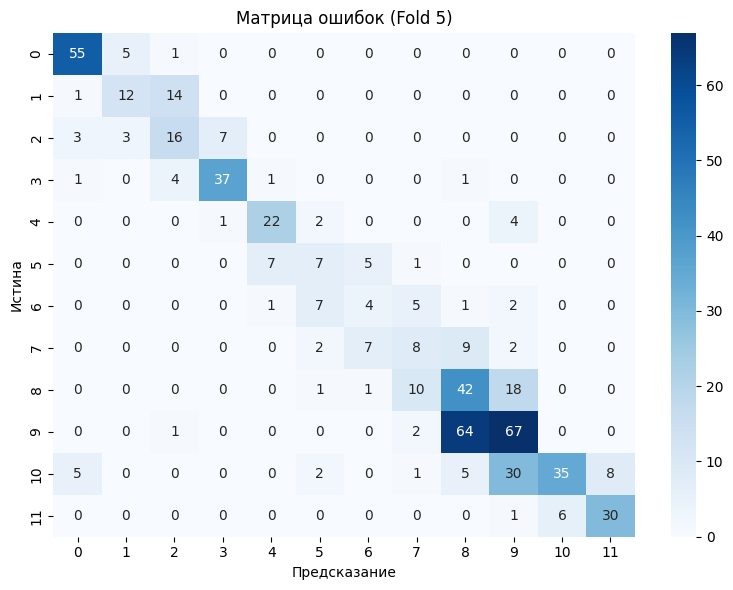

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4219
  Fold 2: F1_macro = 0.6553
  Fold 3: F1_macro = 0.5750
  Fold 4: F1_macro = 0.5932
  Fold 5: F1_macro = 0.5494

  Средний F1 macro: 0.5590 ± 0.0769

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9105    0.8279    0.8672       430
           1     0.5882    0.3871    0.4669       155
           2     0.4123    0.6580    0.5070       193
           3     0.7323    0.7296    0.7310       270
           4     0.5896    0.6271    0.6078       236
           5     0.3357    0.3241    0.3298       145
           6     0.2925    0.2067    0.2422       150
           7     0.3740    0.2565    0.3043       191
           8     0.4849    0.5740    0.5257       392
           9     0.6065    0.7251    0.6605       491
          10     0.8148    0.5906    0.6848       298
          11     0.7761    0.7027    0.7376       148

    accuracy                         0.6054      

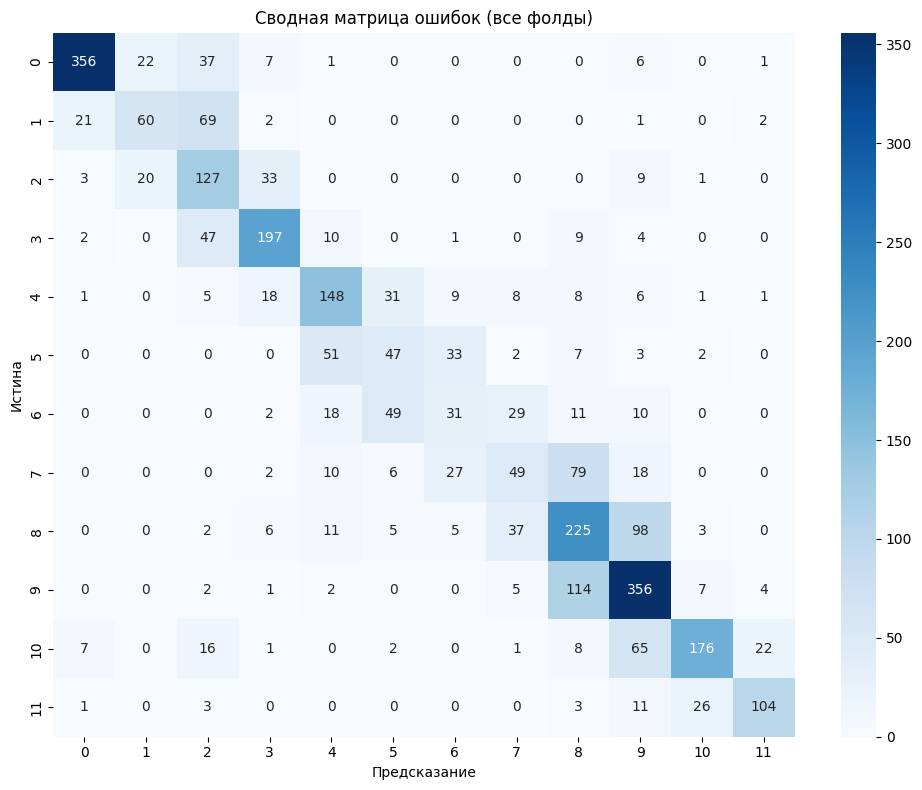

In [9]:
X = df_filtered[elements]
y = df_filtered['Strat']
groups = df_filtered['Well']

param_grid = {
    'depth': [2, 3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.04, 0.05, 0.1, 0.15],
    'iterations': [1000],
    'l2_leaf_reg': [1, 3, 5, 7, 10],
 
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    inner_gkf = GroupKFold(n_splits=5)
    inner_splits = list(inner_gkf.split(X_tr, y_tr, groups_tr))
    inner_train_idx, inner_val_idx = inner_splits[0]

    X_inner_train = X_tr.iloc[inner_train_idx]
    y_inner_train = y_tr.iloc[inner_train_idx]
    X_inner_val = X_tr.iloc[inner_val_idx]
    y_inner_val = y_tr.iloc[inner_val_idx]

    inner_train_wells = sorted(groups_tr.iloc[inner_train_idx].unique())
    inner_val_wells = sorted(groups_tr.iloc[inner_val_idx].unique())

    print(f"  Inner train wells: {inner_train_wells}")
    print(f"  Inner val wells:   {inner_val_wells}")
    print(f"  Inner train: {len(X_inner_train)} проб, Inner val: {len(X_inner_val)} проб")

    best_score = 0
    best_params = {}
    best_model = None

    for params in ParameterGrid(param_grid):
        model = CatBoostClassifier(
            **params,
            loss_function='MultiClass',
            eval_metric='TotalF1',
            random_seed=42,
            verbose=0,
            early_stopping_rounds=50
        )
        model.fit(
            X_inner_train, y_inner_train,
            eval_set=(X_inner_val, y_inner_val),
            use_best_model=True
        )

        y_inner_pred = model.predict(X_inner_val).ravel()
        score = f1_score(y_inner_val, y_inner_pred, average='macro')

        if score > best_score:
            best_score = score
            best_params = params
            best_model = model

    # Предсказания лучшей модели
    y_pred = best_model.predict(X_vl).ravel()
    y_train_pred = best_model.predict(X_tr).ravel()

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"\nЛучшие параметры: {best_params}")
    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()


Результаты кросс-валидации
  Fold 1: F1_macro = 0.4219
  Fold 2: F1_macro = 0.6553
  Fold 3: F1_macro = 0.5750
  Fold 4: F1_macro = 0.5932
  Fold 5: F1_macro = 0.5494

  Средний F1 macro: 0.5590 ± 0.0860

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9105    0.8279    0.8672       430
           1     0.5882    0.3871    0.4669       155
           2     0.4123    0.6580    0.5070       193
           3     0.7323    0.7296    0.7310       270
           4     0.5896    0.6271    0.6078       236
           5     0.3357    0.3241    0.3298       145
           6     0.2925    0.2067    0.2422       150
           7     0.3740    0.2565    0.3043       191
           8     0.4849    0.5740    0.5257       392
           9     0.6065    0.7251    0.6605       491
          10     0.8148    0.5906    0.6848       298
          11     0.7761    0.7027    0.7376       148

    accuracy                         0.6054      

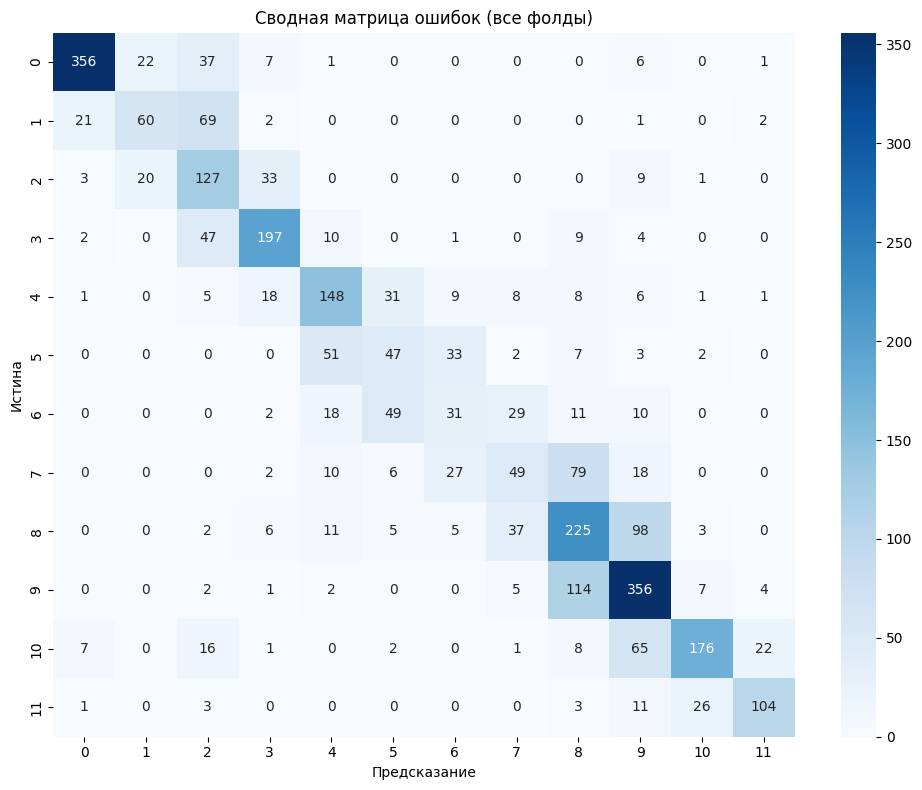

In [10]:
# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

**Вывод:** модель работает по-разному на разных скважинах. Подобранные гиперпараметры не стабильны, для каждого фолда свои. 

**NESTED CV**  Внутренний CV — подбор параметров. Без вложенного цикла подбор параметров и оценка качества были бы на одних и тех же фолдах, и метрика получилась бы завышенной, потому что параметры «подогнаны» под данные, на которых рассчитывались оценки.

В результате каждая проба из датасета получит предсказание класса ровно один раз из того фолда, где скважина была в валидации.

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
  Inner split 1: train=['A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'D1'], val=['A2', 'C7']
  Inner split 2: train=['A2', 'A3', 'A4', 'B1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7'], val=['C1', 'D1']
  Inner split 3: train=['A2', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1'], val=['A3', 'C5']
  Inner split 4: train=['A2', 'A3', 'A4', 'C1', 'C2', 'C5', 'C6', 'C7', 'D1'], val=['B1', 'C3', 'C4']
  Inner split 5: train=['A2', 'A3', 'B1', 'C1', 'C3', 'C4', 'C5', 'C7', 'D1'], val=['A4', 'C2', 'C6']

Лучшие параметры: {'depth': 4, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
Лучший inner F1 (mean): 0.6012
F1 macro (train): 0.8451
F1 macro (val):   0.4496
Gap (train-val):  0.3954

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9677    0.4762    0.6383    

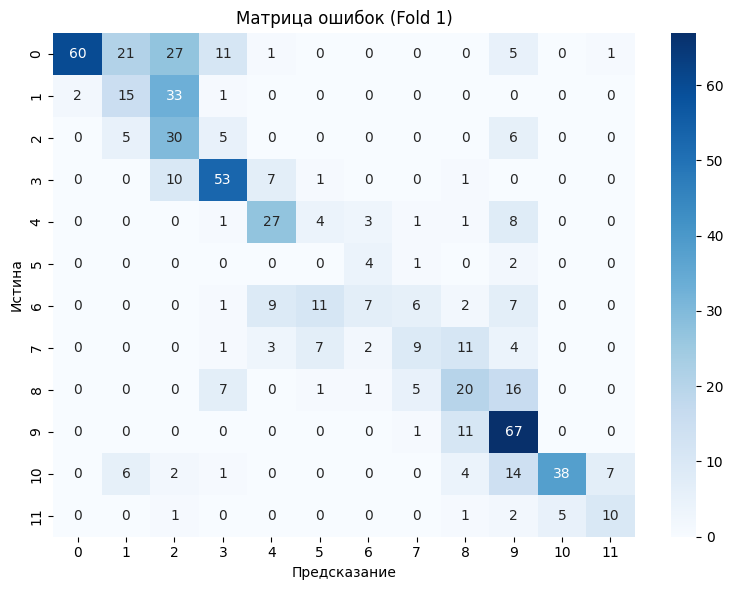

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
  Inner split 1: train=['A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A4', 'B1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1'], val=['A2', 'C1']
  Inner split 3: train=['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C6', 'E1'], val=['C5', 'D1']
  Inner split 4: train=['A1', 'A2', 'A4', 'C1', 'C5', 'C6', 'D1', 'E1'], val=['B1', 'C3', 'C4']
  Inner split 5: train=['A1', 'A2', 'B1', 'C1', 'C3', 'C4', 'C5', 'D1'], val=['A4', 'C6', 'E1']

Лучшие параметры: {'depth': 7, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
Лучший inner F1 (mean): 0.5136
F1 macro (train): 0.9832
F1 macro (val):   0.6730
Gap (train-val):  0.3103

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8023    0.8846    0.8415        78
           1     0.7917

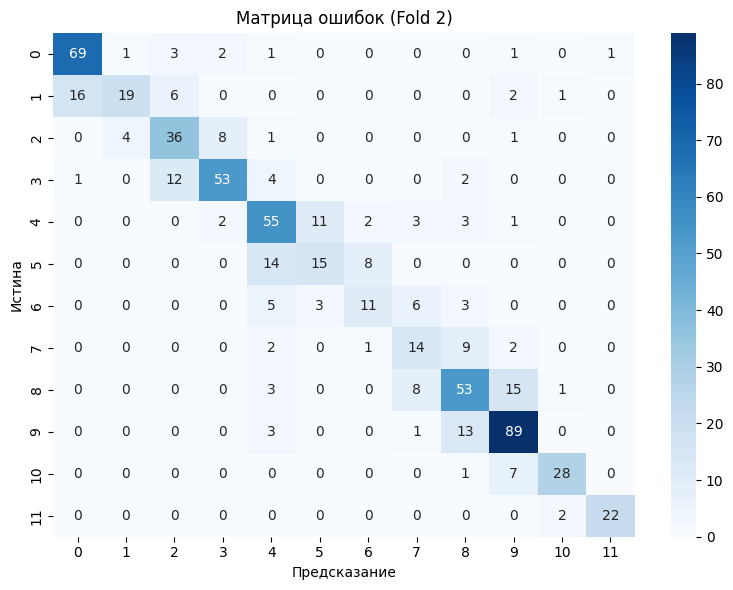

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
  Inner split 1: train=['A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'D1', 'E1'], val=['A2', 'C7']
  Inner split 3: train=['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C6', 'C7', 'E1'], val=['C5', 'D1']
  Inner split 4: train=['A1', 'A2', 'A4', 'C2', 'C5', 'C6', 'C7', 'D1'], val=['A3', 'C3', 'E1']
  Inner split 5: train=['A1', 'A2', 'A3', 'C3', 'C5', 'C7', 'D1', 'E1'], val=['A4', 'C2', 'C6']

Лучшие параметры: {'depth': 3, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
Лучший inner F1 (mean): 0.5691
F1 macro (train): 0.8377
F1 macro (val):   0.5576
Gap (train-val):  0.2801

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8919    0.9565    0.9231        69
           1     0.4000

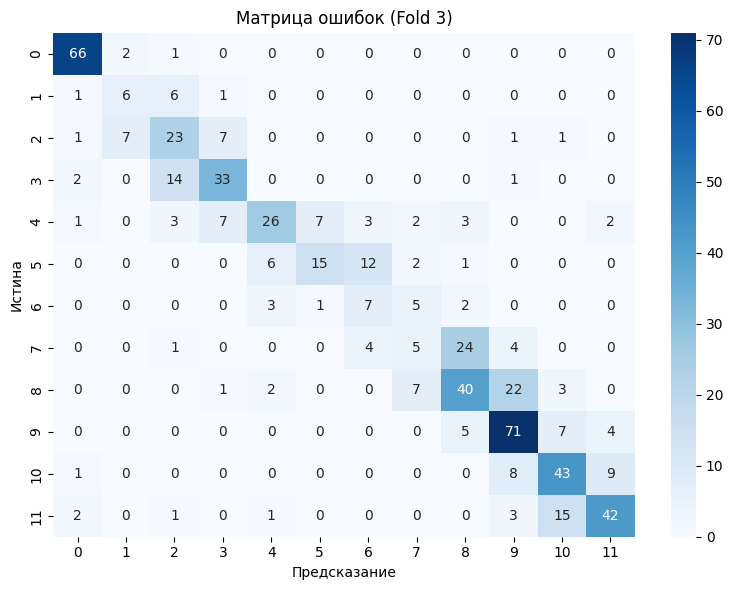

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
  Inner split 1: train=['A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C6', 'D1', 'E1'], val=['C4', 'C7']
  Inner split 3: train=['A1', 'A3', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'E1'], val=['C1', 'D1']
  Inner split 4: train=['A1', 'B1', 'C1', 'C4', 'C6', 'C7', 'D1', 'E1'], val=['A3', 'C2', 'C3']
  Inner split 5: train=['A1', 'A3', 'C1', 'C2', 'C3', 'C4', 'C7', 'D1'], val=['B1', 'C6', 'E1']

Лучшие параметры: {'depth': 5, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
Лучший inner F1 (mean): 0.5844
F1 macro (train): 0.9138
F1 macro (val):   0.5243
Gap (train-val):  0.3896

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9688    0.9688    0.9688        96
           1     0.5455

/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

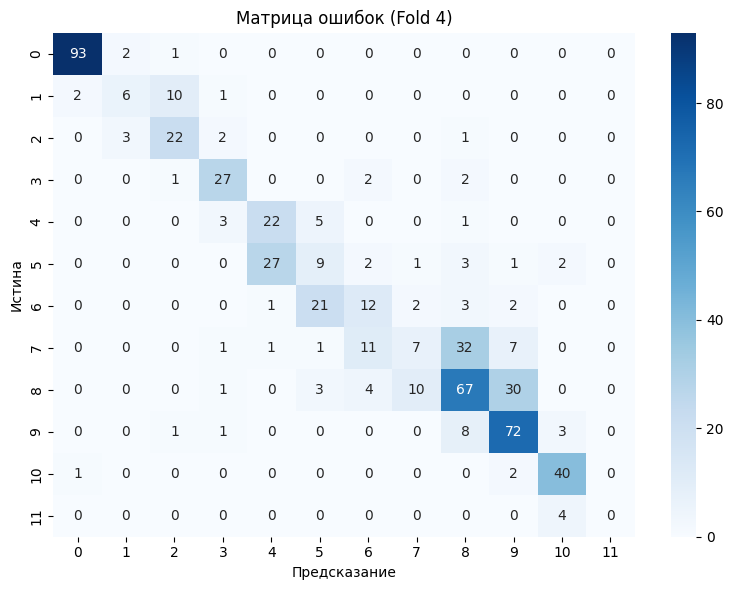

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
  Inner split 1: train=['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C5', 'E1'], val=['C4', 'C7']
  Inner split 3: train=['A1', 'A3', 'A4', 'B1', 'C2', 'C4', 'C5', 'C7', 'E1'], val=['A2', 'C1']
  Inner split 4: train=['A1', 'A2', 'A4', 'B1', 'C1', 'C4', 'C7', 'E1'], val=['A3', 'C2', 'C5']
  Inner split 5: train=['A1', 'A2', 'A3', 'C1', 'C2', 'C4', 'C5', 'C7'], val=['A4', 'B1', 'E1']

Лучшие параметры: {'depth': 5, 'iterations': 1000, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
Лучший inner F1 (mean): 0.5550
F1 macro (train): 0.9693
F1 macro (val):   0.5742
Gap (train-val):  0.3951

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8308    0.8852    0.8571        61
           1     0.5263

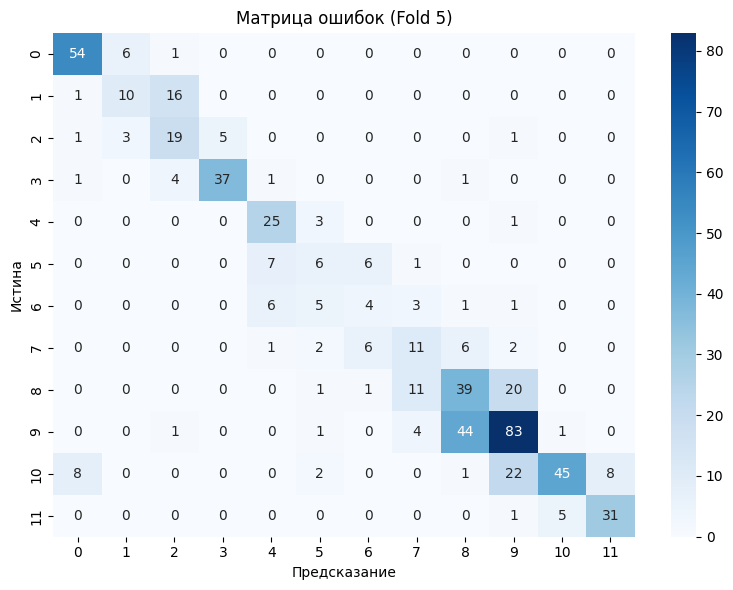

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4496
  Fold 2: F1_macro = 0.6730
  Fold 3: F1_macro = 0.5576
  Fold 4: F1_macro = 0.5243
  Fold 5: F1_macro = 0.5742

  Средний F1 macro: 0.5557 ± 0.0811

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8930    0.7953    0.8413       430
           1     0.4828    0.3613    0.4133       155
           2     0.4561    0.6736    0.5439       193
           3     0.7436    0.7519    0.7477       270
           4     0.5871    0.6568    0.6200       236
           5     0.3333    0.3103    0.3214       145
           6     0.3628    0.2733    0.3118       150
           7     0.3651    0.2408    0.2902       191
           8     0.5227    0.5587    0.5401       392
           9     0.6325    0.7780    0.6977       491
          10     0.7951    0.6510    0.7159       298
          11     0.7664    0.7095    0.7368       148

    accuracy                         0.6189      

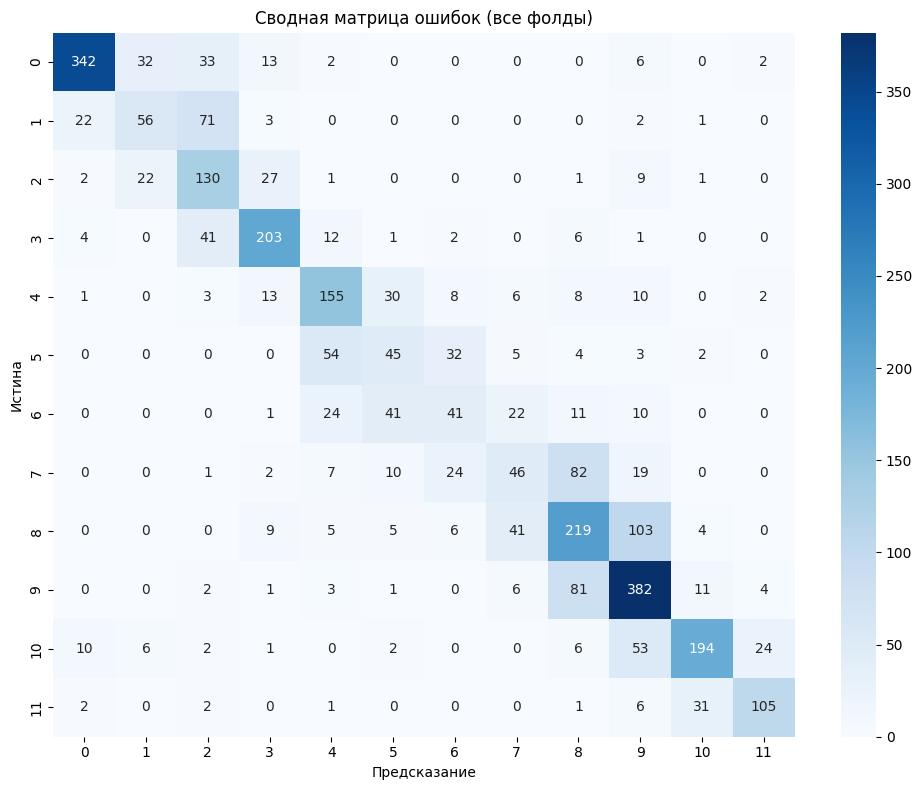

In [13]:
X = df_filtered[elements]
y = df_filtered['Strat']
groups = df_filtered['Well']

param_grid = {
    'depth': [2, 3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1, 0.15],
    'iterations': [1000],
    'l2_leaf_reg': [1, 3, 5, 7, 10],
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    # Внутренний CV
    inner_gkf = GroupKFold(n_splits=5)
    inner_splits = list(inner_gkf.split(X_tr, y_tr, groups_tr))

    for i, (in_tr, in_vl) in enumerate(inner_splits, 1):
        in_tr_wells = sorted(groups_tr.iloc[in_tr].unique())
        in_vl_wells = sorted(groups_tr.iloc[in_vl].unique())
        print(f"  Inner split {i}: train={in_tr_wells}, val={in_vl_wells}")

    best_score = 0
    best_params = {}
    best_iteration = None  

    for params in ParameterGrid(param_grid):
        inner_scores = []
        inner_iterations = []

        for inner_train_idx, inner_val_idx in inner_splits:
            X_inner_train = X_tr.iloc[inner_train_idx]
            y_inner_train = y_tr.iloc[inner_train_idx]
            X_inner_val = X_tr.iloc[inner_val_idx]
            y_inner_val = y_tr.iloc[inner_val_idx]

            model = CatBoostClassifier(
                **params,
                loss_function='MultiClass',
                eval_metric='TotalF1',
                random_seed=42,
                verbose=0,
                early_stopping_rounds=50,
                task_type='GPU',
                devices='0'
            )
            model.fit(
                X_inner_train, y_inner_train,
                eval_set=(X_inner_val, y_inner_val),
                use_best_model=True
            )

            y_inner_pred = model.predict(X_inner_val).ravel()
            inner_scores.append(f1_score(y_inner_val, y_inner_pred, average='macro'))
            inner_iterations.append(model.get_best_iteration())

        mean_inner_score = np.mean(inner_scores)

        if mean_inner_score > best_score:
            best_score = mean_inner_score
            best_params = params
            best_iteration = int(np.mean(inner_iterations))

    final_params = best_params.copy()
    final_params['iterations'] = best_iteration
    # Финальная модель на всём train-фолде
    best_model = CatBoostClassifier(
        **final_params,
        loss_function='MultiClass',
        eval_metric='TotalF1',
        random_seed=42,
        verbose=0,
        task_type='GPU',
        devices='0'
    )
    best_model.fit(X_tr, y_tr)

    # Предсказания
    y_pred = best_model.predict(X_vl).ravel()
    y_train_pred = best_model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"\nЛучшие параметры: {final_params}")
    print(f"Лучший inner F1 (mean): {best_score:.4f}")
    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

**Вывод:** Средний F1 macro на внешней валидации составил 0.556 ± 0.081. Средний F1 macro на train — 0.910 ± 0.068, gap train−val = 0.354. Разброс F1 между фолдами — от 0.45 (Fold 1) до 0.673 (Fold 2).

**NESTED CV дополнена, сохраняется число итераций по фолдам, записывается best_iteration для каждого фолда**

**Эксперимент 4**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
  Inner split 1: train=['A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'D1'], val=['A2', 'C7']
  Inner split 2: train=['A2', 'A3', 'A4', 'B1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7'], val=['C1', 'D1']
  Inner split 3: train=['A2', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1'], val=['A3', 'C5']
  Inner split 4: train=['A2', 'A3', 'A4', 'C1', 'C2', 'C5', 'C6', 'C7', 'D1'], val=['B1', 'C3', 'C4']
  Inner split 5: train=['A2', 'A3', 'B1', 'C1', 'C3', 'C4', 'C5', 'C7', 'D1'], val=['A4', 'C2', 'C6']

  Лучшие параметры: {'depth': 4, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
  Лучший inner F1 (mean): 0.6012
  Среднее число итераций (best_iteration): 129

  F1 macro (train): 0.9515
  F1 macro (val):   0.4852
  Gap (train-val):  0.4663

Classification Report (Fold 1)
              precision    recall  f1-score   support

         

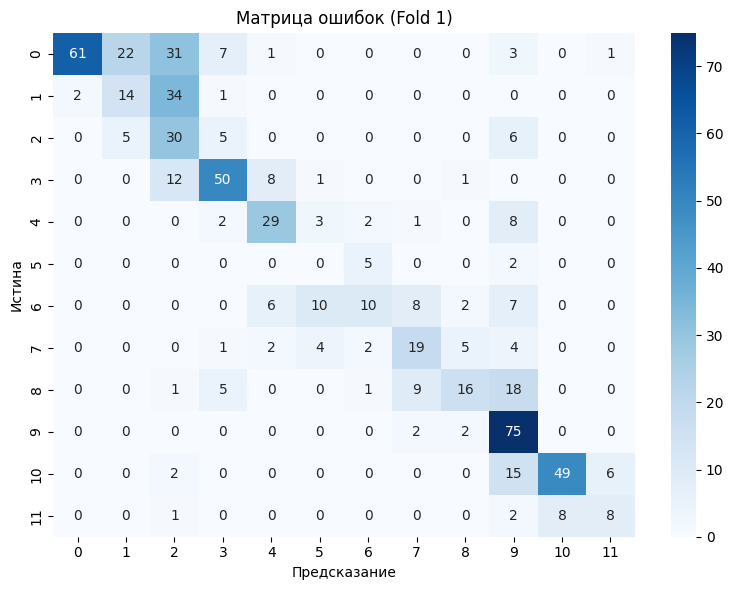

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
  Inner split 1: train=['A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A4', 'B1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1'], val=['A2', 'C1']
  Inner split 3: train=['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C6', 'E1'], val=['C5', 'D1']
  Inner split 4: train=['A1', 'A2', 'A4', 'C1', 'C5', 'C6', 'D1', 'E1'], val=['B1', 'C3', 'C4']
  Inner split 5: train=['A1', 'A2', 'B1', 'C1', 'C3', 'C4', 'C5', 'D1'], val=['A4', 'C6', 'E1']

  Лучшие параметры: {'depth': 7, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
  Лучший inner F1 (mean): 0.5141
  Среднее число итераций (best_iteration): 141

  F1 macro (train): 1.0000
  F1 macro (val):   0.6842
  Gap (train-val):  0.3158

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8068    0.9103    0.

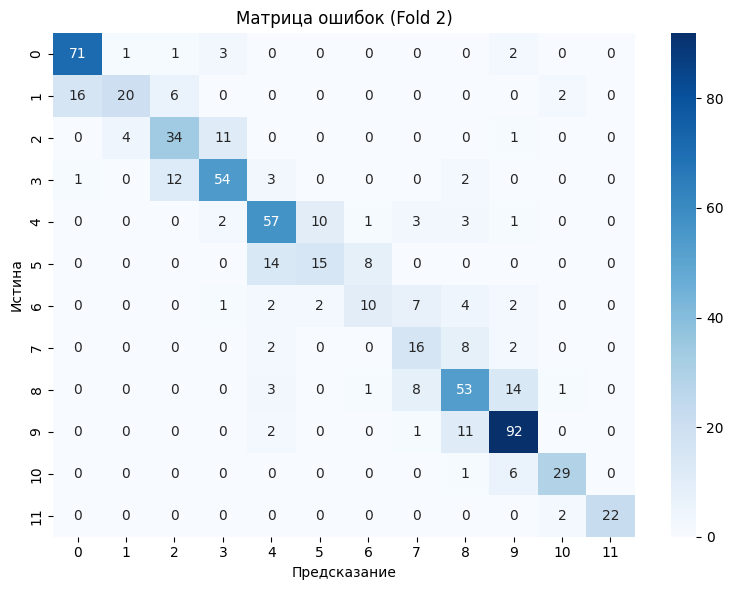

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
  Inner split 1: train=['A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'D1', 'E1'], val=['A2', 'C7']
  Inner split 3: train=['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C6', 'C7', 'E1'], val=['C5', 'D1']
  Inner split 4: train=['A1', 'A2', 'A4', 'C2', 'C5', 'C6', 'C7', 'D1'], val=['A3', 'C3', 'E1']
  Inner split 5: train=['A1', 'A2', 'A3', 'C3', 'C5', 'C7', 'D1', 'E1'], val=['A4', 'C2', 'C6']

  Лучшие параметры: {'depth': 3, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
  Лучший inner F1 (mean): 0.5691
  Среднее число итераций (best_iteration): 194

  F1 macro (train): 0.8863
  F1 macro (val):   0.5661
  Gap (train-val):  0.3203

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9054    0.9710    0.

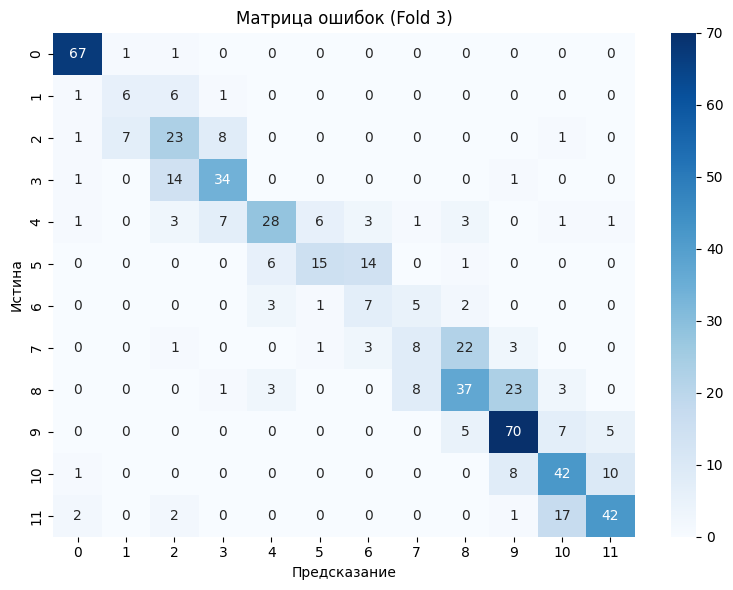

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
  Inner split 1: train=['A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C6', 'D1', 'E1'], val=['C4', 'C7']
  Inner split 3: train=['A1', 'A3', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'E1'], val=['C1', 'D1']
  Inner split 4: train=['A1', 'B1', 'C1', 'C4', 'C6', 'C7', 'D1', 'E1'], val=['A3', 'C2', 'C3']
  Inner split 5: train=['A1', 'A3', 'C1', 'C2', 'C3', 'C4', 'C7', 'D1'], val=['B1', 'C6', 'E1']

  Лучшие параметры: {'depth': 5, 'l2_leaf_reg': 1, 'learning_rate': 0.15}
  Лучший inner F1 (mean): 0.5844
  Среднее число итераций (best_iteration): 156

  F1 macro (train): 0.9843
  F1 macro (val):   0.5388
  Gap (train-val):  0.4454

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9588    0.9688    0.

/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

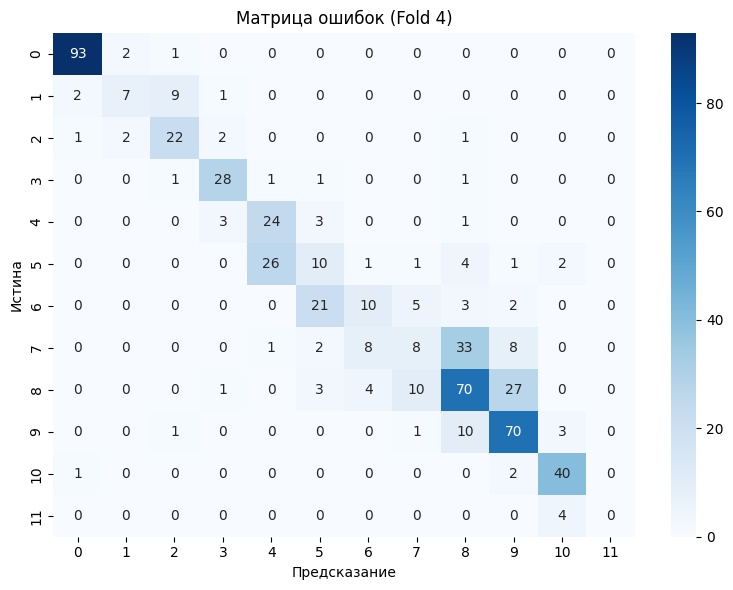

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
  Inner split 1: train=['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1'], val=['A1']
  Inner split 2: train=['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C5', 'E1'], val=['C4', 'C7']
  Inner split 3: train=['A1', 'A3', 'A4', 'B1', 'C2', 'C4', 'C5', 'C7', 'E1'], val=['A2', 'C1']
  Inner split 4: train=['A1', 'A2', 'A4', 'B1', 'C1', 'C4', 'C7', 'E1'], val=['A3', 'C2', 'C5']
  Inner split 5: train=['A1', 'A2', 'A3', 'C1', 'C2', 'C4', 'C5', 'C7'], val=['A4', 'B1', 'E1']

  Лучшие параметры: {'depth': 6, 'l2_leaf_reg': 1, 'learning_rate': 0.07}
  Лучший inner F1 (mean): 0.5672
  Среднее число итераций (best_iteration): 258

  F1 macro (train): 0.9595
  F1 macro (val):   0.5680
  Gap (train-val):  0.3915

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.7887    0.9180    0.

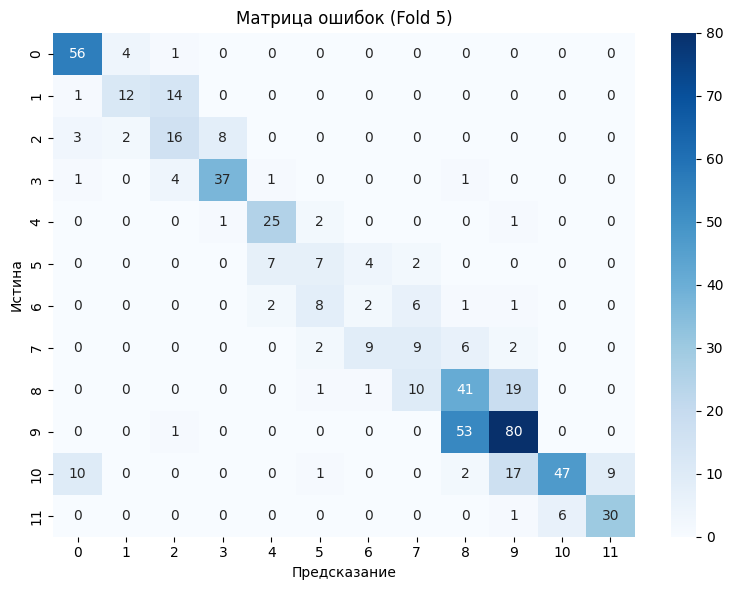

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4852, best_iteration = 129
  Fold 2: F1_macro = 0.6842, best_iteration = 141
  Fold 3: F1_macro = 0.5661, best_iteration = 194
  Fold 4: F1_macro = 0.5388, best_iteration = 156
  Fold 5: F1_macro = 0.5680, best_iteration = 258

  Средний F1 macro: 0.5685 ± 0.0728
  Среднее best_iteration: 176 ± 52

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8855    0.8093    0.8457       430
           1     0.5413    0.3806    0.4470       155
           2     0.4401    0.6477    0.5241       193
           3     0.7409    0.7519    0.7463       270
           4     0.6367    0.6907    0.6626       236
           5     0.3643    0.3241    0.3431       145
           6     0.3679    0.2600    0.3047       150
           7     0.4054    0.3141    0.3540       191
           8     0.5358    0.5536    0.5445       392
           9     0.6482    0.7882    0.7114       491
          10 

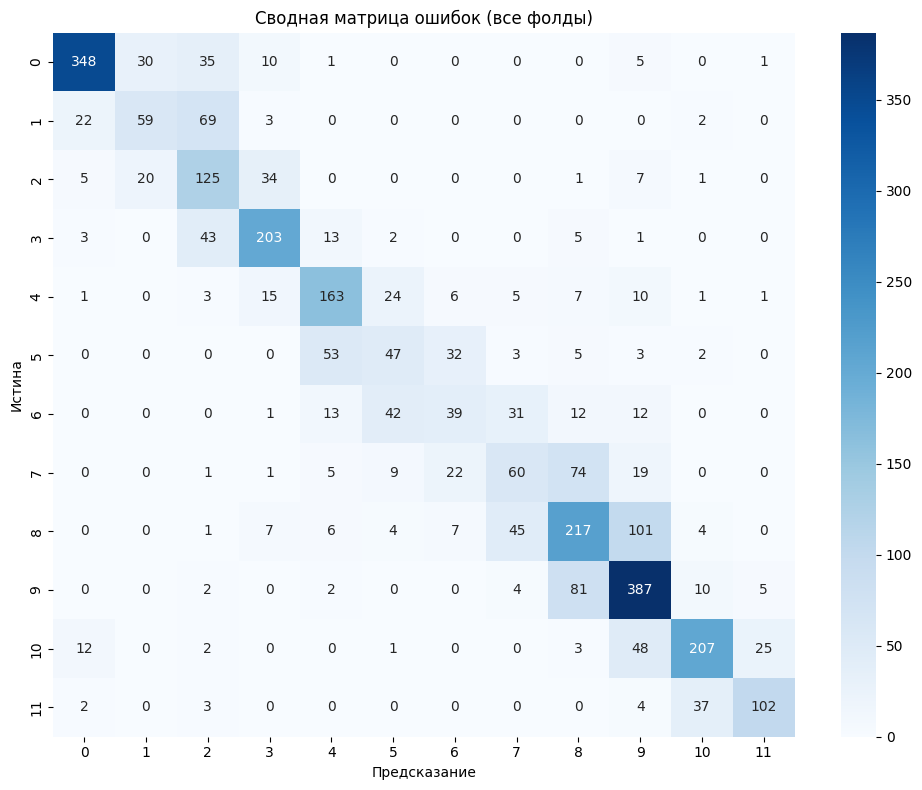

In [9]:
X = df_filtered[elements]
y = df_filtered['Strat']
groups = df_filtered['Well']

param_grid = {
    'depth': [2, 3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1, 0.15],     
    'l2_leaf_reg': [1, 3, 5, 7, 10],
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
best_iterations_per_fold = []   

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    # Внутренний CV
    inner_gkf = GroupKFold(n_splits=5)
    inner_splits = list(inner_gkf.split(X_tr, y_tr, groups_tr))

    for i, (in_tr, in_vl) in enumerate(inner_splits, 1):
        in_tr_wells = sorted(groups_tr.iloc[in_tr].unique())
        in_vl_wells = sorted(groups_tr.iloc[in_vl].unique())
        print(f"  Inner split {i}: train={in_tr_wells}, val={in_vl_wells}")

    best_score = 0
    best_params = {}
    best_iteration = None

    for params in ParameterGrid(param_grid):
        inner_scores = []
        inner_iterations = []

        for inner_train_idx, inner_val_idx in inner_splits:
            X_inner_train = X_tr.iloc[inner_train_idx]
            y_inner_train = y_tr.iloc[inner_train_idx]
            X_inner_val = X_tr.iloc[inner_val_idx]
            y_inner_val = y_tr.iloc[inner_val_idx]

            model = CatBoostClassifier(
                **params,
                iterations=1000,
                loss_function='MultiClass',
                eval_metric='TotalF1',
                random_seed=42,
                verbose=0,
                early_stopping_rounds=50,
                task_type='GPU',
                devices='0'
            )
            model.fit(
                X_inner_train, y_inner_train,
                eval_set=(X_inner_val, y_inner_val),
                use_best_model=True
            )

            y_inner_pred = model.predict(X_inner_val).ravel()
            inner_scores.append(f1_score(y_inner_val, y_inner_pred, average='macro'))
            inner_iterations.append(model.get_best_iteration())

        mean_inner_score = np.mean(inner_scores)

        if mean_inner_score > best_score:
            best_score = mean_inner_score
            best_params = params
            best_iteration = int(np.mean(inner_iterations))

    print(f"\n  Лучшие параметры: {best_params}")
    print(f"  Лучший inner F1 (mean): {best_score:.4f}")
    print(f"  Среднее число итераций (best_iteration): {best_iteration}")

    # Финальная модель на всём train-фолде
    best_model = CatBoostClassifier(
        **best_params,
        iterations=300,
        loss_function='MultiClass',
        eval_metric='TotalF1',
        random_seed=42,
        verbose=0,
        task_type='GPU',
        devices='0'
    )
    best_model.fit(X_tr, y_tr)

    # Сохраняем число итераций
    best_iterations_per_fold.append(best_iteration)

    # Предсказания
    y_pred = best_model.predict(X_vl).ravel()
    y_train_pred = best_model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"\n  F1 macro (train): {f1_train:.4f}")
    print(f"  F1 macro (val):   {f1_val:.4f}")
    print(f"  Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # Матрица ошибок
    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}, best_iteration = {best_iterations_per_fold[i-1]}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"  Среднее best_iteration: {np.mean(best_iterations_per_fold):.0f} "
      f"± {np.std(best_iterations_per_fold, ddof=1):.0f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()